<hr size=5 color='#002883'>

<p align="center"> <font size=7 color='#002883'> Elaboração de cartas sinóticas para identificação de Sistemas de Alta (quente ou fria) e Baixa (quente ou fria) pressão

<hr size=5 color='#002883'>

<p align="left"> <font size=5 color='#002883'> Professores:  

* Prof. Dra. Rita Yuri Ynoue

<p align="left"> <font size=5 color='#002883'> Monitor PAE:

* Ronald Guiuseppi Ramírez Nina [PhD. Candidate in Atmospheric Sciences]
* email: ronald.ramirez.nina@alumni.usp.br / ronald.ramirez.nina@usp.br

<hr size=5 color='#002883'>

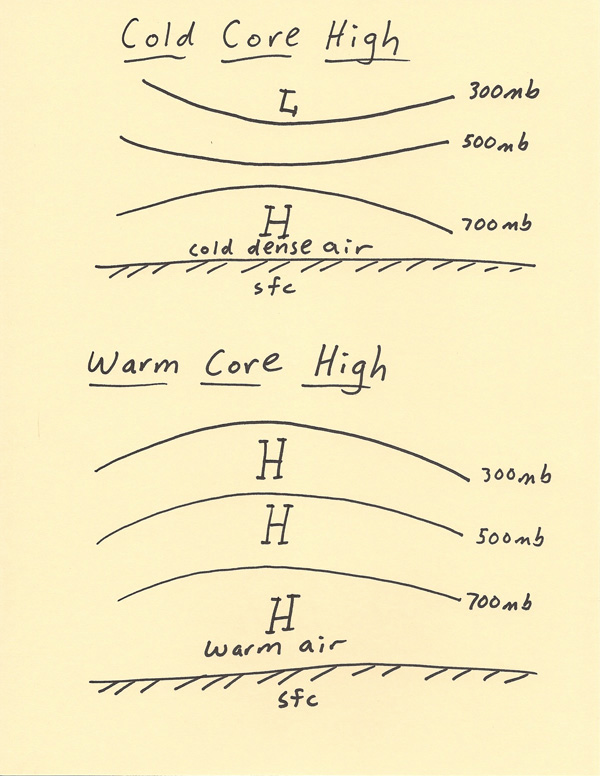

**Extraído de: https://www.theweatherprediction.com/habyhints2/612/**

**Link de site principal: https://www.theweatherprediction.com/**

<hr size=5 color='#002883'>

# <font size=6 color='#002883'> **1. preparação do Colab** <font>

<font size=4 color='#002883'> Executar as três células de abaixo: <font>

<font size=4 color='#002883'>1.1. Montar o drive para acesso a nossa pasta de trabalho <font>

In [1]:
# @title #### <font color='#002883'> Montar o drive para a importação da livraria utilities_new_version <font>
%%capture

from google.colab import drive
drive.mount('/content/drive')

<font size=4 color='#002883'>1.2. Adicionar o caminho do sistema para a importação do utilities_new_version.py <font>

In [2]:
# @title #### <font color='#002883'> Adicionar o caminho do Drive ao caminho do sistema para importação de módulos <font>
%%capture

import sys
sys.path.append('/content/drive/MyDrive/')

<font size=4 color='#002883'>1.3. Instação de livrarias <font>

In [3]:
# @title #### <font color='#002883'> Instalar livrarias <font>
%%capture

!pip install imgaug
!pip install siphon

# Instalando a Biblioteca Pygrib
!pip install pygrib
#print('\n')

# Instalando a Biblioteca Cartopy
!pip install cartopy
!pip install shapely --no-binary shapely --force
#print('\n')

# Instalando a Biblioteca MetPy
!pip install "numpy<2.0" metpy --upgrade
#!pip install MetPy
#print('\n')

# Instalando a Biblioteca Boto3
!pip install boto3
#print('\n')

# Instalando a Biblioteca NetCDF4
!pip install netcdf4
#print('\n')

# Instalando a biblioteca para trabalhar arquivos .grib com a livraria xarray
!pip install -q cfgrib eccodes

# Instalando / atualizando a Biblioteca GDAL
!apt-add-repository -y ppa:ubuntugis/ubuntugis-unstable
!add-apt-repository -y ppa:ubuntugis/ppa
!apt-get install gdal-bin
!pip install 'gdal==3.0.4'
#print('\n')

# Install ImageMagick
!sudo apt install imagemagick
#print('\n')

<font size=4 color='#002883'>1.4. Instação de livrarias para imagens interativas e em 3-Dimensões<font>

In [ ]:
# @title #### <font color='#002883'> Instalação de Plotly, dash e kaleido <font>
#%%capture
!pip install --upgrade --force-reinstall --no-cache-dir plotly dash kaleido

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 197.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 279.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 230.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 876.3/876.3 kB 323.3 MB/s  0:00:00
  Attempting uninstall: zipp
    Found existing installation: zipp 4.1.1
    Uninstalling zipp-4.1.1:
      Successfully uninstalled zipp-4.1.1
  Attempting uninstall: urllib3
    Found existing installation: urllib3 2.5.0
    Uninstalling urllib3-2.5.0:
      Successfully uninstalled urllib3-2.5.0
  Attempting uninstall: typing_extensions
    Found existing installation: typing_extensions 4.16.0
    Uninstalling typing_extensions-4.16.0:
      Successfully uninstalled typing_extensions-4.16.0
  Attempting uninstall: simplejson
    Found existing installation: simplejson 4.2.0
    Uninstalling simplejson-4.2.0:
      Successfully uninstalled simplejson-4.2.0
  Attempting uninstall: setup

<font size=4 color='#002883'>1.4. Reiniciar a sessão de trabalho. Necessário para a importação do módulo de Metpy <font>

In [ ]:
# @title #### <font color='#002883'> Reiniciar sessão devido ao modulo do Metpy <font>
%%capture

import os
os.kill(os.getpid(), 9)

<font size=4 color='#002883'> **2. Fazer downloand de arquivos complementários (e.g., shapefile de estados e provincias do Brasil e outros paises). Além disso, fazer o download do arquivo utilities.py para o uso no processamento de imagens de satélite da série GOES. Download do arquivo CPT para o realce do canal infravermelho e vapor d'água.** <font>

In [1]:
# @title #### <font color='#002883'> Baixar arquivos complementários <font>
%%capture

# Baixando o shapefile dos estados brasileiros
!wget -c https://geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/malhas_municipais/municipio_2019/Brasil/BR/br_unidades_da_federacao.zip
#print('\n')

# Descomprimindo o arquivo de shapefile dos estados brasileiros
!unzip -o br_unidades_da_federacao.zip
#print('\n')

# Baixando o shapefile dos estados / províncias mundiais
!wget -c https://www.naturalearthdata.com/http//www.naturalearthdata.com/download/10m/cultural/ne_10m_admin_1_states_provinces.zip
#print('\n')

# Descomprimindo o arquivo de shapefile dos estados / províncias mundiais
!unzip -o ne_10m_admin_1_states_provinces.zip
#print('\n')

# Download da arquivo CPT exemplo (para realce de canais IR)
!wget -c https://www.dropbox.com/s/fdgnaqt91cy3x97/IR4AVHRR6.cpt
#print('\n')

# Download da arquivo CPT exemplo (para realce de canais WV)
!wget -c https://www.dropbox.com/s/4l9fys6pv5c68xk/SVGAWVX_TEMP.cpt
#print('\n')

<font size=4 color='#002883'> **3. Importar livrarias.** <font>

In [2]:
# @title #### <font color='#002883'> Importar livrarias para o processamento dos dados <font>
%%capture

from datetime import datetime
import os
import requests
import time as t
import sys

# Livrarias para leitura, processamento e plot de dados NetCDF
from netCDF4 import Dataset
from osgeo import gdal
import matplotlib.pyplot as plt
import cartopy, cartopy.crs as ccrs
import cartopy.io.shapereader as shpreader
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
from matplotlib import cm
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.dates import DateFormatter
import matplotlib as mpl
import matplotlib.colors as colors
import matplotlib.dates as mdates
import matplotlib.colors as mcolors

from datetime import timedelta, date, datetime
import pygrib
import numpy as np
import xarray as xr
gdal.PushErrorHandler('CPLQuietErrorHandler')

# Livrarias para o cálculo de campos meteorológicos
from metpy.units import units
import metpy.calc as mpcalc
import numpy.ma as ma
from scipy.ndimage import gaussian_filter

# Carregar a nova versão do utilities_new_version.py
#import sys
#folder_path = '/content/drive/MyDrive/USP-CURSOS/MONITORIA/METEOROLOGIA-SINOTICA-II-2026'
#if folder_path not in sys.path:
#    sys.path.append(folder_path)
#from utilities_new_version import download_CMI
#from utilities_new_version import reproject
#from utilities_new_version import loadCPT

<font size=4 color='red'> **4.1. Função para o download dos dados do modelo Global forecasting System (GFS).** <font>

In [3]:
# @title #### <font color='#002883'> Construir função para o download dos arquivos do GFS <font>
%%capture

# Link (select "grib filter" and check "Show the URL only for web programming" to verify the URL's):
# https://nomads.ncep.noaa.gov/

def download_gfs(date, iii):

    # Create the URL's based on the resolution
    if (resolution == '25'):
        url = 'https://nomads.ncep.noaa.gov/cgi-bin/filter_gfs_0p'+resolution+'.pl?file=gfs.t'+hour_run+'z.pgrb2.0p'+resolution+'.f'+str(hour).zfill(3)+'&all_lev=on&all_var=on&subregion=&leftlon='+min_lon+'&rightlon='+max_lon+'&toplat='+max_lat+'&bottomlat='+min_lat+'&dir=%2Fgfs.'+date+'%2F'+hour_run+'%2Fatmos'
        file_name = 'gfs.t'+hour_run+'z.pgrb2.0p'+resolution+'.f'+str(hour).zfill(3)
        res = 'prgb2.0p'+resolution+'.f'
    elif (resolution == '50'):
        url = 'https://nomads.ncep.noaa.gov/cgi-bin/filter_gfs_0p'+resolution+'.pl?file=gfs.t'+hour_run+'z.pgrb2full.0p'+resolution+'.f'+str(hour).zfill(3)+'&all_lev=on&all_var=on&subregion=&leftlon='+min_lon+'&rightlon='+max_lon+'&toplat='+max_lat+'&bottomlat='+min_lat+'&dir=%2Fgfs.'+date+'%2F'+hour_run+'%2Fatmos'
        file_name = 'gfs.t'+hour_run+'z.pgrb2.0p'+resolution+'.f'+str(hour).zfill(3)
        res = 'prgb2.0p'+resolution+'.f'
    elif (resolution == '1'):
        url = 'https://nomads.ncep.noaa.gov/cgi-bin/filter_gfs_'+resolution+'p00.pl?file=gfs.t'+hour_run+'z.pgrb2.'+resolution+'p00.f'+str(hour).zfill(3)+'&all_lev=on&all_var=on&subregion=&leftlon='+min_lon+'&rightlon='+max_lon+'&toplat='+max_lat+'&bottomlat='+min_lat+'&dir=%2Fgfs.'+date+'%2F'+hour_run+'%2Fatmos'
        file_name = 'gfs.t'+hour_run+'z.pgrb2.'+resolution+'p00.f'+str(hour).zfill(3)
        res = 'prgb2.'+resolution+'p00.f'

    # Print the file name
    print("File name: ", file_name)
    # Sends a GET request to the specified url
    myfile = requests.get(url)

    # Download the file
    open(dir + '//' + file_name, 'wb').write(myfile.content)

<font size=4 color='red'> **4.2. Função para o download de dados do Geostationary Operational Environmental Satellite - 19 (GOES-19) do Amazon Web Services (AWS).** <font>

In [4]:
# @title #### <font color='#002883'> Construir função para o download dos arquivos do GOES-19 <font>
%%capture

# ==========================================================================================================
# Training: Python and GOES-19 Imagery: Functions for download data from AWS
# ==========================================================================================================
# Required modules
import os                                # Miscellaneous operating system interfaces
import numpy as np                       # Import the Numpy package
import colorsys                          # To make convertion of colormaps
import boto3                             # Amazon Web Services (AWS) SDK for Python
from botocore import UNSIGNED            # boto3 config
from botocore.config import Config       # boto3 config
import math                              # Mathematical functions
from datetime import datetime            # Basic Dates and time types
from osgeo import osr                    # Python bindings for GDAL
from osgeo import gdal                   # Python bindings for GDAL

#from netCDF4 import Dataset          # Read / Write NetCDF4 files
#import matplotlib.pyplot as plt      # Plotting library
#import cartopy, cartopy.crs as ccrs  # Plot maps
##import sys
#from datetime import timedelta, date, datetime   # Manipulate dates

# ==========================================================================================================
def loadCPT(path):

    try:
        f = open(path)
    except:
        print ("File ", path, "not found")
        return None

    lines = f.readlines()

    f.close()

    x = np.array([])
    r = np.array([])
    g = np.array([])
    b = np.array([])

    colorModel = 'RGB'

    for l in lines:
        ls = l.split()
        if l[0] == '#':
            if ls[-1] == 'HSV':
                colorModel = 'HSV'
                continue
            else:
                continue
        if ls[0] == 'B' or ls[0] == 'F' or ls[0] == 'N':
            pass
        else:
            x=np.append(x,float(ls[0]))
            r=np.append(r,float(ls[1]))
            g=np.append(g,float(ls[2]))
            b=np.append(b,float(ls[3]))
            xtemp = float(ls[4])
            rtemp = float(ls[5])
            gtemp = float(ls[6])
            btemp = float(ls[7])

        x=np.append(x,xtemp)
        r=np.append(r,rtemp)
        g=np.append(g,gtemp)
        b=np.append(b,btemp)

    if colorModel == 'HSV':
        for i in range(r.shape[0]):
            rr, gg, bb = colorsys.hsv_to_rgb(r[i]/360.,g[i],b[i])
        r[i] = rr ; g[i] = gg ; b[i] = bb

    if colorModel == 'RGB':
        r = r/255.0
        g = g/255.0
        b = b/255.0

    xNorm = (x - x[0])/(x[-1] - x[0])

    red   = []
    blue  = []
    green = []

    for i in range(len(x)):
        red.append([xNorm[i],r[i],r[i]])
        green.append([xNorm[i],g[i],g[i]])
        blue.append([xNorm[i],b[i],b[i]])

    colorDict = {'red': red, 'green': green, 'blue': blue}

    return colorDict

# ==========================================================================================================

def download_CMI(yyyymmddhhmn, band, path_dest):

    os.makedirs(path_dest, exist_ok=True)

    year = datetime.strptime(yyyymmddhhmn, "%Y%m%d%H%M").strftime("%Y")
    day_of_year = datetime.strptime(yyyymmddhhmn, "%Y%m%d%H%M").strftime("%j")
    hour = datetime.strptime(yyyymmddhhmn, "%Y%m%d%H%M").strftime("%H")
    min = datetime.strptime(yyyymmddhhmn, "%Y%m%d%H%M").strftime("%M")

    # AMAZON repository information (MUDADO PARA GOES-19)
    bucket_name = "noaa-goes19"
    product_name = "ABI-L2-CMIPF"

    # Initializes the S3 client
    s3_client = boto3.client("s3", config=Config(signature_version=UNSIGNED))

    # File structure (MUDADO PARA _G19_)
    prefix = f"{product_name}/{year}/{day_of_year}/{hour}/OR_{product_name}-M6C{int(band):02.0f}_G19_s{year}{day_of_year}{hour}{min}"

    # Search for the file on the server
    s3_result = s3_client.list_objects_v2(
        Bucket=bucket_name, Prefix=prefix, Delimiter="/"
    )

    if "Contents" not in s3_result:
        print(f"No files found for the date: {yyyymmddhhmn}, Band-{band}")
        return -1
    else:
        for obj in s3_result["Contents"]:
            key = obj["Key"]
            file_name = key.split("/")[-1].split(".")[0]

            if os.path.exists(f"{path_dest}/{file_name}.nc"):
                print(f"File {path_dest}/{file_name}.nc exists")
            else:
                print(f"Downloading file {path_dest}/{file_name}.nc")
                s3_client.download_file(
                    bucket_name, key, f"{path_dest}/{file_name}.nc"
                )
    return f"{file_name}"

# ==========================================================================================================
def download_PROD(yyyymmddhhmn, product_name, path_dest):

    os.makedirs(path_dest, exist_ok=True)

    year = datetime.strptime(yyyymmddhhmn, "%Y%m%d%H%M").strftime("%Y")
    day_of_year = datetime.strptime(yyyymmddhhmn, "%Y%m%d%H%M").strftime("%j")
    hour = datetime.strptime(yyyymmddhhmn, "%Y%m%d%H%M").strftime("%H")
    min = datetime.strptime(yyyymmddhhmn, "%Y%m%d%H%M").strftime("%M")

    # AMAZON repository information (MUDADO PARA GOES-19)
    bucket_name = "noaa-goes19"

    s3_client = boto3.client("s3", config=Config(signature_version=UNSIGNED))

    # File structure (MUDADO PARA _G19_)
    prefix = f"{product_name}/{year}/{day_of_year}/{hour}/OR_{product_name}-M6_G19_s{year}{day_of_year}{hour}{min}"

    s3_result = s3_client.list_objects_v2(
        Bucket=bucket_name, Prefix=prefix, Delimiter="/"
    )

    if "Contents" not in s3_result:
        print(f"No files found for the date: {yyyymmddhhmn}, Product-{product_name}")
        return -1
    else:
        for obj in s3_result["Contents"]:
            key = obj["Key"]
            file_name = key.split("/")[-1].split(".")[0]

            if os.path.exists(f"{path_dest}/{file_name}.nc"):
                print(f"File {path_dest}/{file_name}.nc exists")
            else:
                print(f"Downloading file {path_dest}/{file_name}.nc")
                s3_client.download_file(
                    bucket_name, key, f"{path_dest}/{file_name}.nc"
                )
    return f"{file_name}"

# ==========================================================================================================
def download_GLM(yyyymmddhhmnss, path_dest):

    os.makedirs(path_dest, exist_ok=True)

    year = datetime.strptime(yyyymmddhhmnss, "%Y%m%d%H%M%S").strftime("%Y")
    day_of_year = datetime.strptime(yyyymmddhhmnss, "%Y%m%d%H%M%S").strftime("%j")
    hour = datetime.strptime(yyyymmddhhmnss, "%Y%m%d%H%M%S").strftime("%H")
    min = datetime.strptime(yyyymmddhhmnss, "%Y%m%d%H%M%S").strftime("%M")
    seg = datetime.strptime(yyyymmddhhmnss, "%Y%m%d%H%M%S").strftime("%S")

    # AMAZON repository information (MUDADO PARA GOES-19)
    bucket_name = "noaa-goes19"

    s3_client = boto3.client("s3", config=Config(signature_version=UNSIGNED))

    product_name = "GLM-L2-LCFA"
    # File structure (MUDADO PARA _G19_)
    prefix = f"{product_name}/{year}/{day_of_year}/{hour}/OR_{product_name}_G19_s{year}{day_of_year}{hour}{min}{seg}"

    s3_result = s3_client.list_objects_v2(
        Bucket=bucket_name, Prefix=prefix, Delimiter="/"
    )

    if "Contents" not in s3_result:
        print(f"No files found for the date: {yyyymmddhhmnss}, Product-{product_name}")
        return -1
    else:
        for obj in s3_result["Contents"]:
            key = obj["Key"]
            file_name = key.split("/")[-1].split(".")[0]

            if os.path.exists(f"{path_dest}/{file_name}.nc"):
                print(f"File {path_dest}/{file_name}.nc exists")
            else:
                print(f"Downloading file {path_dest}/{file_name}.nc")
                s3_client.download_file(
                    bucket_name, key, f"{path_dest}/{file_name}.nc"
                )
    return f"{file_name}"

# ==========================================================================================================
# Function to convert lat / lon extent to GOES-19 extents
def convertExtent2GOESProjection(extent):
    GOES19_HEIGHT = 35786023.0
    # Longitude de sub-satélite do GOES-19 (GOES-East operacional)
    GOES19_LONGITUDE = -75.2

    a, b = latlon2xy(extent[1], extent[0])
    c, d = latlon2xy(extent[3], extent[2])
    return (a * GOES19_HEIGHT, c * GOES19_HEIGHT, b * GOES19_HEIGHT, d * GOES19_HEIGHT)

# ==========================================================================================================
# Functions to convert lat / lon extent to array indices
def geo2grid(lat, lon, nc):

    # Apply scale and offset
    xscale, xoffset = nc.variables['x'].scale_factor, nc.variables['x'].add_offset
    yscale, yoffset = nc.variables['y'].scale_factor, nc.variables['y'].add_offset

    x, y = latlon2xy(lat, lon)
    col = (x - xoffset)/xscale
    lin = (y - yoffset)/yscale
    return int(lin), int(col)

# ==========================================================================================================
def latlon2xy(lat, lon):
    # goes_imagery_projection:semi_major_axis
    req = 6378137 # meters
    #  goes_imagery_projection:inverse_flattening
    invf = 298.257222096
    # goes_imagery_projection:semi_minor_axis
    rpol = 6356752.31414 # meters
    e = 0.0818191910435
    # goes_imagery_projection:perspective_point_height + goes_imagery_projection:semi_major_axis
    H = 42164160 # meters
    # goes_imagery_projection: longitude_of_projection_origin
    lambda0 = -1.308996939

    # Convert to radians
    latRad = lat * (math.pi/180)
    lonRad = lon * (math.pi/180)

    # (1) geocentric latitude
    Phi_c = math.atan(((rpol * rpol)/(req * req)) * math.tan(latRad))
    # (2) geocentric distance to the point on the ellipsoid
    rc = rpol/(math.sqrt(1 - ((e * e) * (math.cos(Phi_c) * math.cos(Phi_c)))))
    # (3) sx
    sx = H - (rc * math.cos(Phi_c) * math.cos(lonRad - lambda0))
    # (4) sy
    sy = -rc * math.cos(Phi_c) * math.sin(lonRad - lambda0)
    # (5)
    sz = rc * math.sin(Phi_c)

    # x,y
    x = math.asin((-sy)/math.sqrt((sx*sx) + (sy*sy) + (sz*sz)))
    y = math.atan(sz/sx)

    return x, y

# ==========================================================================================================
# Function to reproject the data
def reproject(file_name, ncfile, array, extent, undef):

    # Read the original file projection and configure the output projection
    source_prj = osr.SpatialReference()
    source_prj.ImportFromProj4(ncfile.GetProjectionRef())

    target_prj = osr.SpatialReference()
    target_prj.ImportFromProj4("+proj=longlat +ellps=WGS84 +datum=WGS84 +no_defs")

    # Reproject the data
    GeoT = ncfile.GetGeoTransform()
    driver = gdal.GetDriverByName('MEM')
    raw = driver.Create('raw', array.shape[0], array.shape[1], 1, gdal.GDT_Float32)
    raw.SetGeoTransform(GeoT)
    raw.GetRasterBand(1).WriteArray(array)

    # Define the parameters of the output file
    kwargs = {'format': 'netCDF', \
            'srcSRS': source_prj, \
            'dstSRS': target_prj, \
            'outputBounds': (extent[0], extent[3], extent[2], extent[1]), \
            'outputBoundsSRS': target_prj, \
            'outputType': gdal.GDT_Float32, \
            'srcNodata': undef, \
            'dstNodata': 'nan', \
            'resampleAlg': gdal.GRA_NearestNeighbour}

    # Write the reprojected file on disk
    gdal.Warp(file_name, raw, **kwargs)


<font size=4 color='#002883'> **5. Download dos dados do modelo Global forecasting System (GFS). É necessário editar a data Year = YYYY, month = mm, day = dd e hour = hh. Os dados do GFS só estão disponíveis até 5 dias atrás da data atual.** <font>

In [5]:
# @title #### <font color='#002883'> Download dos dados do GFS <font>
#%%capture

# Configurar a data de acesso aos dados do GFS
year = 2026
month = 10
day = 24
hour = 00

# Extensão desejada - COLOCAR AQUI ENTRE ASPAS POIS É UMA STRING
# longitude de -180 a 180
min_lon = '-122.50'
max_lon = '12.50'
min_lat = '-80.0'
max_lat = '25.0'

print('---------------------------------------')
print('GFS Download (NOMADS) - Script started.')
print('---------------------------------------')

# Start the time counter
start_time = t.time()

# Data desejada (Únicamente os últimos 10 dias!): Formato - 'YYYY, MM, DD, HH'
dt = datetime(year, month, day, hour)
yyyymmddhhmn = (f'{dt:%Y%m%d%H}00') # Data e hora da imagem de satélite

#-----------------------------------------------------------------------------------------------------------

# Download diretório
dir = "Samples"; os.makedirs(dir, exist_ok=True)

# Data desajada (Únicamente os últimos 10 dias!): Formato - 'YYYYMMDD'
date = (f'{dt:%Y%m%d}')

# Resolução espacial desejada: '25' or '50' or '1'
resolution = '25' #'1'

# Hora de execução: '00' or '06' or '12' or '18'
#hour_run = '00'
hour_run=(f'{dt:%H}')

# Horas de previsão
hour_ini = 0  # Init time
hour_end = 0 # End time
hour_int = 3  # Interval

if (resolution == '25'):
  res = 'pgrb2.0p'+resolution+'.f'
elif (resolution == '50'):
  res = 'pgrb2.0p'+resolution+'.f'
elif (resolution == '1'):
  res = 'pgrb2.'+resolution+'p00.f'

#-----------------------------------------------------------------------------------------------------------

# Download loop
for hour in range(hour_ini, hour_end + 1, hour_int):
    print('\n---------------------')
    print('Downloading GFS File:')
    print('---------------------')
    print('Resolution: ' + resolution)
    print('Date: ' + date)
    print('Run: ' + hour_run)
    print('Forecast Hour: f' + str(hour).zfill(3))
    # Call the download function
    download_gfs(date,hour)

# End the time counter
print('\nTotal Processing Time:', round((t.time() - start_time),2), 'seconds.')

---------------------------------------
GFS Download (NOMADS) - Script started.
---------------------------------------

---------------------
---------------------
Resolution: 25
Date: 20261024
Run: 00
Forecast Hour: f000
File name:  gfs.t00z.pgrb2.0p25.f000

Total Processing Time: 19.19 seconds.


<font size=4 color='#002883'> **6. Download dos dados de satélite do GOES-19.** <font>

In [6]:
# @title #### <font color='#002883'> Download de GOES-19 <font>
#%%capture

# Seleção da extensão [min. lon, min. lat, max. lon, max. lat]
# Lembrar que longitude está definida entre -180 e 180
extent = [float(min_lon), float(min_lat), float(max_lon), float(max_lat)]

# Input e output directorios
input = "/content/Samples"; os.makedirs(input, exist_ok=True)
output = "/content/Output"; os.makedirs(output, exist_ok=True)

#-----------------------------------------------------------------------------------------------------------
date = (f'{dt:%Y%m%d}')
yyyymmddhhmn = (f'{dt:%Y%m%d%H}00') # Data e hora da imagem de satélite
hour_run=(f'{dt:%H}')

# Download the ABI file channel 13 - Clean IR
file_ir = download_CMI(yyyymmddhhmn, 13, input)

# Variable
var = 'CMI'
# Abrir o dado
img = gdal.Open(f'NETCDF:{input}/{file_ir}.nc:' + var)

# Ler os metadados
metadata = img.GetMetadata()
scale = float(metadata.get(var + '#scale_factor'))
offset = float(metadata.get(var + '#add_offset'))
undef = float(metadata.get(var + '#_FillValue'))
dtime = metadata.get('NC_GLOBAL#time_coverage_start')

# Carregar os dados
ds_cmi = img.ReadAsArray(0, 0, img.RasterXSize, img.RasterYSize).astype(float)

# Aplicar a escala, offset e converter de Kelvin para Graus Celcius
ds_cmi = (ds_cmi * scale + offset) - 273.15

# Reprojeção do arquivo
filename_ret = f'{output}/IR_{yyyymmddhhmn}.nc'
reproject(filename_ret, img, ds_cmi, extent, undef)

# Ler a imagem do GOES-19 reprojetada
file = Dataset(filename_ret)

# Acessar aos valores dos pixel
data = file.variables['Band1'][:]

File /content/Samples/OR_ABI-L2-CMIPF-M6C13_G19_s20262970000213_e20262970009534_c20262970009596.nc exists


/usr/local/lib/python3.13/dist-packages/osgeo/gdal.py:312: FutureWarning: Neither gdal.UseExceptions() nor gdal.DontUseExceptions() has been explicitly called. In GDAL 4.0, exceptions will be enabled by default.
  warnings.warn(


<font size=4 color='#002883'> **7. Definir os campos meteorológicos por níveis do GFS.** <font>

In [7]:
# @title #### <font color='#002883'> Definir as variáveis do GFS por níveis <font>
%%capture

# Ler o dado grib do GFS
grib = pygrib.open(f'Samples/gfs.t{hour_run}z.{res}000')

# Selecionar a variável
mslp = grib.select(name='Pressure reduced to MSL')[0]

# Acessar informação do arquivo
init  = str(mslp.analDate)      # Init date / time
run   = str(mslp.hour).zfill(2) # Run
ftime = str(mslp.forecastTime)  # Forecast hour
valid = str(mslp.validDate)     # Valid date / time
print('Init: ' + init + ' UTC')
print('Run: ' + run + 'Z')
print('Forecast: +' + ftime)
print('Valid: ' + valid + ' UTC')

# ========================================================================
# VARIÁVEIS DE SUPERFÍCIE:
# - Pressão reduzida ao nível medio do mar
# - Taxa de precipitação
#
# VARIÁVEL DE TODA A COLUNA ATMOSFÉRICA:
# - Água precipitável
# ========================================================================
# Ler a data da região específica
# Longitude tem que estar entre 0 e 360 graus
mslp, lats, lons = mslp.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])
# Converter para hPa
mslp = mslp / 100

# Selecionar a variável
prtwt = grib.select(name='Precipitable water')[0]
prtwt = prtwt.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]
# Quero somente valores maiores que 0
mask_prtwt = ma.masked_less(prtwt, 0).mask
prtwt[mask_prtwt] = np.nan

# Busca a variável de taxa de precipitação na superfície
precip_rate = grib.select(name='Precipitation rate', typeOfLevel='surface')[0]

# ========================================================================
# ALTURA GEOPOTENCIAL
# ========================================================================
# Select the variable
hght_1000 = grib.select(name='Geopotential height', typeOfLevel = 'isobaricInhPa', level = 1000)[0]
# Read the data for a specific region
hght_1000 = hght_1000.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# Select the variable
hght_850 = grib.select(name='Geopotential height', typeOfLevel = 'isobaricInhPa', level = 850)[0]
# Read the data for a specific region
hght_850 = hght_850.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# Select the variable
hght_700 = grib.select(name='Geopotential height', typeOfLevel = 'isobaricInhPa', level = 700)[0]
# Read the data for a specific region
hght_700 = hght_700.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# Select the variable
hght_500 = grib.select(name='Geopotential height', typeOfLevel = 'isobaricInhPa', level = 500)[0]
# Read the data for a specific region
hght_500 = hght_500.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# Select the variable
hght_250 = grib.select(name='Geopotential height', typeOfLevel = 'isobaricInhPa', level = 250)[0]
# Read the data for a specific region
hght_250 = hght_250.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# ========================================================================
# ESPESSURA
# ========================================================================
# Calculate and smooth 1000-500 hPa thickness
thickness_1000_500 = hght_500 - hght_1000
# Calculate and smooth 1000-850 hPa thickness
thickness_1000_850 = hght_850 - hght_1000

# ========================================================================
# COMPONENTES ZONAL (U) E MERIDIONAL (V) DO VENTO
# ========================================================================
# Select the variable
u_1000 = grib.select(name='U component of wind', typeOfLevel = 'isobaricInhPa', level = 1000)[0]
# Read the data for a specific region
u_1000, lats, lons = u_1000.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])
# Select the variable
v_1000 = grib.select(name='V component of wind', typeOfLevel = 'isobaricInhPa', level = 1000)[0]
# Read the data for a specific region
v_1000 = v_1000.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# Selecionar a variável
u_925 = grib.select(name='U component of wind', typeOfLevel = 'isobaricInhPa', level = 925)[0]
# Ler a data para a região específica
u_925, lats, lons = u_925.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])
# Selecionar a variável
v_925 = grib.select(name='V component of wind', typeOfLevel = 'isobaricInhPa', level = 925)[0]
# Ler a data para a região específica
v_925 = v_925.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# Select the variable
u_850 = grib.select(name='U component of wind', typeOfLevel = 'isobaricInhPa', level = 850)[0]
# Read the data for a specific region
u_850, lats, lons = u_850.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])
# Select the variable
v_850 = grib.select(name='V component of wind', typeOfLevel = 'isobaricInhPa', level = 850)[0]
# Read the data for a specific region
v_850 = v_850.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# Select the variable
u_700 = grib.select(name='U component of wind', typeOfLevel = 'isobaricInhPa', level = 700)[0]
# Read the data for a specific region
u_700, lats, lons = u_700.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])
# Select the variable
v_700 = grib.select(name='V component of wind', typeOfLevel = 'isobaricInhPa', level = 700)[0]
# Read the data for a specific region
v_700 = v_700.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# Select the variable
u_500 = grib.select(name='U component of wind', typeOfLevel = 'isobaricInhPa', level = 500)[0]
# Read the data for a specific region
u_500, lats, lons = u_500.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])
# Select the variable
v_500 = grib.select(name='V component of wind', typeOfLevel = 'isobaricInhPa', level = 500)[0]
# Read the data for a specific region
v_500 = v_500.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# Selecionar a variável
u_250 = grib.select(name='U component of wind', typeOfLevel = 'isobaricInhPa', level = 250)[0]
# Ler a data para a região específica
u_250, lats, lons = u_250.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])
# Selecionar a variável
v_250 = grib.select(name='V component of wind', typeOfLevel = 'isobaricInhPa', level = 250)[0]
# Ler a data para a região específica
v_250 = v_250.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# ========================================================================
# OMEGA
# ========================================================================
# Selecionar a variável
w_850 = grib.select(name='Vertical velocity', typeOfLevel = 'isobaricInhPa', level = 850)[0]
# Ler a data para a região específica
w_850 = w_850.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]
# Selecionar a variável
w_500 = grib.select(name='Vertical velocity', typeOfLevel = 'isobaricInhPa', level = 500)[0]
# Ler a data para a região específica
w_500 = w_500.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# ========================================================================
# UMIDADE ESPECÍFICA
# ========================================================================
# Selecionar a variável
spch_850 = grib.select(name='Specific humidity', typeOfLevel = 'isobaricInhPa', level = 850)[0]
# Ler os dados da região de estudo
spch_850 = spch_850.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# ========================================================================
# TEMPERATURA DO AR
# ========================================================================
# Selecionar a variável
temp_850 = grib.select(name='Temperature', typeOfLevel = 'isobaricInhPa', level = 850)[0]
# Ler a data para a região específica
temp_850 = temp_850.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]
temp_850 = units('K') * temp_850

# Selecionar a variável
temp_700 = grib.select(name='Temperature', typeOfLevel = 'isobaricInhPa', level = 700)[0]
# Ler a data para a região específica
temp_700 = temp_700.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]
temp_700 = units('K') * temp_700

# Selecionar a variável
temp_500 = grib.select(name='Temperature', typeOfLevel='isobaricInhPa', level=500)[0]
# Ler a data para a região específica
temp_500 = temp_500.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]
temp_500 = units('K') * temp_500

# Select the variable
temp_250 = grib.select(name='Temperature', typeOfLevel = 'isobaricInhPa', level = 250)[0]
# Read the data for a specific region
temp_250 = temp_250.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]
temp_250 = units('K') * temp_250

# ========================================================================
# UMIDADE RELATIVA
# ========================================================================
# Selecionar a variável
relhum_800 = grib.select(name='Relative humidity', typeOfLevel = 'isobaricInhPa', level = 800)[0]
# Ler a data para a região específica
relhum_800 = relhum_800.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]
# Selecionar a variável
relhum_850 = grib.select(name='Relative humidity', typeOfLevel = 'isobaricInhPa', level = 850)[0]
# Ler a data para a região específica
relhum_850 = relhum_850.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]
# Selecionar a variável
relhum_700 = grib.select(name='Relative humidity', typeOfLevel = 'isobaricInhPa', level = 700)[0]
# Ler a data para a região específica
relhum_700 = relhum_700.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# calculando umidade relativa média entre 800 e 700 hPa
relhum = (relhum_800 + relhum_850 + relhum_700)/3

# Calculando com metpy
dx, dy = mpcalc.lat_lon_grid_deltas(lons, lats)

# ========================================================================
# NIVEL = 1000 hPa
# ========================================================================
u_1000 = units('m/s') * u_1000
v_1000 = units('m/s') * v_1000

# ========================================================================
# NIVEL = 925 hPa
# ========================================================================
# Calculando divergencia em 925 hPa
nivel_925 = 925
pressure = units('Pa') * nivel_925 * 100
u_925 = units('m/s') * u_925
v_925 = units('m/s') * v_925
# Calcular divergência
div_925 = mpcalc.divergence(u_925, v_925, dx=dx, dy=dy)
# Mascara para só obter a convergencia
mask_conv = ma.masked_greater_equal(div_925, 0).mask
div_925[mask_conv] = np.nan

# ========================================================================
# NIVEL = 850 hPa
# ========================================================================
nivel_850 = 850
pressure_850 = units('Pa') * nivel_850 * 100
u_850 = units('m/s') * u_850
v_850 = units('m/s') * v_850
# Cálculo das componentes do Q-vetor
uqvect, vqvect = mpcalc.q_vector(u=u_850, v=v_850, temperature=temp_850, pressure=pressure_850, dx=dx, dy=dy)
# Cálculo da divergência dos Q-vetores calculado anteriormente
q_div = 2*mpcalc.divergence(uqvect, vqvect, dx=dx, dy=dy)
# Cálculo da temperatura potencial para o cálculo da frontogenesis
theta = mpcalc.potential_temperature(pressure = pressure_850, temperature = temp_850)
# Cálculo da temperatura do ponto de orvalho
dewp = mpcalc.dewpoint_from_specific_humidity(pressure = pressure_850, temperature = temp_850, specific_humidity = spch_850)
# Cálculo da tempeatura potencial equivalente
thetae = mpcalc.equivalent_potential_temperature(pressure = pressure_850, temperature = temp_850, dewpoint = dewp)
# Cálculo da frontogenesis
fronto = mpcalc.frontogenesis(potential_temperature = theta, u = u_850, v = v_850, dx = dx, dy = dy)
# Fator de conversão das unidades da frontogenesis K por 100 km por 3 h
convert_to_per_100km_3h = 1000*100*3600*3
# Calculando a vorticidade em 850 hPa
zeta_850 = mpcalc.vorticity(u_850,v_850, dx = dx, dy = dy)
# Quero somente os valores menores que 0
mask_zeta = ma.masked_greater_equal(zeta_850, 0).mask
zeta_850[mask_zeta] = np.nan
# Cálculo da advecção de temperatura
#T = temp_850
adv = mpcalc.advection(temp_850, u = u_850, v = v_850, dx = dx, dy = dy)

# Quero somente os valores negativos de omega
mask_omega = ma.masked_greater_equal(w_850, 0).mask
w_850[mask_omega] = np.nan

# ========================================================================
# NIVEL = 250 hPa
# ========================================================================
# Calculando divergencia em 250 hPa
nivel_700 = 700
pressure_700 = units('Pa') * nivel_700 * 100
u_700 = units('m/s') * u_700
v_700 = units('m/s') * v_700

# ========================================================================
# NIVEL = 500 hPa
# ========================================================================
nivel_500 = 500
pressure_500 = units('Pa') * nivel_500 * 100
u_500 = units('m/s') * u_500
v_500 = units('m/s') * v_500

# Cálculo das componentes do Q-vetor
uqvect_500, vqvect_500 = mpcalc.q_vector(u = u_500, v = v_500, temperature=temp_500, pressure=pressure_500, dx=dx, dy=dy)
# Cálculo da divergência dos Q-vetores
q_div_500 = 2*mpcalc.divergence(uqvect_500, vqvect_500, dx=dx, dy=dy)
# Cálculo da vorticidade
zeta_500 = mpcalc.vorticity(u_500,v_500, dx = dx, dy = dy)
#Quero somente os valores menores que 0
#mask_zeta = ma.masked_greater_equal(zeta_500, 0).mask
#zeta_500[mask_zeta] = np.nan
# Cálculo da advecção da vorticidade
#T = zeta_500
adv_zeta = mpcalc.advection(zeta_500, u = u_500, v = v_500, dx = dx, dy = dy)

# Só valores negativos de omega
mask_omega = ma.masked_greater_equal(w_500, 0).mask
w_500[mask_omega] = np.nan

# ========================================================================
# NIVEL = 250 hPa
# ========================================================================
# Calculando divergencia em 250 hPa
nivel_250 = 250
pressure_250 = units('Pa') * nivel_250 * 100
u_250 = units('m/s') * u_250
v_250 = units('m/s') * v_250

# Use MetPy to calculate the wind speed for colorfill plot, change units to knots from m/s
speed_jet = mpcalc.wind_speed(u_250, v_250)
#Quero somente os valores maiores que 30 m/s
mask_jet = ma.masked_less_equal(speed_jet, 30).mask
speed_jet[mask_jet] = np.nan

# Cálculo da divergência
div_250 = mpcalc.divergence(u_250, v_250, dx=dx, dy=dy)
# Só valores de convergência
mask_div = ma.masked_less_equal(div_250, 0).mask
div_250[mask_div] = np.nan

# Cálculo das componentes do Q-vetor
uqvect_250, vqvect_250 = mpcalc.q_vector(u = u_250, v = v_250, temperature=temp_250, pressure=pressure_250, dx=dx, dy=dy)
# Cálculo da divergência dos Q-vetores
q_div_250 = 2*mpcalc.divergence(uqvect_250, vqvect_250, dx=dx, dy=dy)


<font size=4 color='red'> **Observação: Para listar as variáveis disponíveis pelo modelo GFS, rodar a seguinte célular.** <font>

In [8]:
# @title #### <font color='red'> Listar variáveis do modelo GFS <font>
%%capture

for grb in grib:
    print(grb)  # Imprime diretamente: número, nome, unidades, tipo de nível e valor do nível

grib.close()

<font size=4 color='#002883'> **8. Converter a Analysis do modelo GFS do formato .grib2 para o formato .nc (NetCDF). Com os dados no formato NetCDF é possível fazer os corter verticais para identificação do Jato Subtropical (JST) e do Jato Polar (JP)** <font>


<font size=4 color='red'> **Observação: Só as variáveis com níveis de pressão ("typeOfLevel": "isobaricInhPa") que serão transformadas do formato .grib2 para o formato .nc** <font>

In [9]:
# @title #### <font color='#002883'> Transformar do formato .grib2 para .nc (Só as variáveis com níveis de pressão que serão transformadas) <font>
#%%capture

import logging

# Silencia os logs do cfgrib
logging.getLogger("cfgrib").setLevel(logging.CRITICAL)

ds = xr.open_dataset(
    f'Samples/gfs.t{hour_run}z.{res}000',
    engine="cfgrib",
    backend_kwargs={
        "filter_by_keys": {
            "typeOfLevel": "isobaricInhPa"
        },
        "indexpath": ""
    }
)

ds

<xarray.Dataset> Size: 301MB
Dimensions:        (isobaricInhPa: 33, latitude: 421, longitude: 541)
Coordinates:
  * isobaricInhPa  (isobaricInhPa) float64 264B 1e+03 975.0 950.0 ... 2.0 1.0
  * latitude       (latitude) float64 3kB -80.0 -79.75 -79.5 ... 24.5 24.75 25.0
  * longitude      (longitude) float64 4kB -122.5 -122.2 -122.0 ... 12.25 12.5
    time           datetime64[ns] 8B ...
    step           timedelta64[ns] 8B ...
    valid_time     datetime64[ns] 8B ...
Data variables:
    gh             (isobaricInhPa, latitude, longitude) float32 30MB ...
    t              (isobaricInhPa, latitude, longitude) float32 30MB ...
    r              (isobaricInhPa, latitude, longitude) float32 30MB ...
    q              (isobaricInhPa, latitude, longitude) float32 30MB ...
    w              (isobaricInhPa, latitude, longitude) float32 30MB ...
    wz             (isobaricInhPa, latitude, longitude) float32 30MB ...
    u              (isobaricInhPa, latitude, longitude) float32 30MB ...
    v              (isobaricInhPa, latitude, longitude) float32 30MB ...
    absv           (isobaricInhPa, latitude, longitude) float32 30MB ...
    o3mr           (isobaricInhPa, latitude, longitude) float32 30MB ...
Attributes:
    GRIB_edition:            2
    GRIB_centre:             kwbc
    GRIB_centreDescription:  US National Weather Service - NCEP
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             US National Weather Service - NCEP
    history:                 2026-10-25T01:20 GRIB to CDM+CF via cfgrib-0.9.1...

<font size=4 color='#002883'> **9. Calculando a velocidade do vento considerando só as componentes zonal (u) e meridional (v). Além disso, calculando a Temperatura Potencial e Vorticidade Potencial Baroclínica fazendo uso da livraria Metpy** <font>

In [10]:
# @title #### <font color='#002883'> Cálculo da magnitude da velocidade do vento, Temperatura Potencial, e Vorticidade Potencial Baroclínica <font>
#%%capture

# MAGNITUDE DO VENTO
ds['wind_speed'] = mpcalc.wind_speed(ds['u'], ds['v'])  #np.sqrt(ds['u']**2 + ds['v']**2)

# TEMPERATURA POTENCIAL
ds['theta'] = mpcalc.potential_temperature(ds['isobaricInhPa'], ds['t'])

# VORTICIDADE POTENCIAL BAROCLÍNICAL
ds['pv'] = mpcalc.potential_vorticity_baroclinic(
    potential_temperature=ds['theta'],
    pressure=ds['isobaricInhPa'],
    u=ds['u'],
    v=ds['v']
)
ds['pv'].attrs['units'] = 'K * m^2 / (kg * s)'

# Converter o resultado para Unidades de Vorticidade Potencial (PVU)
# 1 PVU = 10^-6 K * m^2 / (kg * s)
ds['pv_pvu'] = ds['pv'] * 1e6
# Atualiza os atributos para exibição correta
ds['pv_pvu'].attrs['units'] = 'PVU'
ds

/tmp/ipykernel_38448/184319864.py:11: UserWarning: More than one time coordinate present for variable  "theta".
  ds['pv'] = mpcalc.potential_vorticity_baroclinic(


<xarray.Dataset> Size: 511MB
Dimensions:        (isobaricInhPa: 33, latitude: 421, longitude: 541)
Coordinates:
  * isobaricInhPa  (isobaricInhPa) float64 264B 1e+03 975.0 950.0 ... 2.0 1.0
  * latitude       (latitude) float64 3kB -80.0 -79.75 -79.5 ... 24.5 24.75 25.0
  * longitude      (longitude) float64 4kB -122.5 -122.2 -122.0 ... 12.25 12.5
    time           datetime64[ns] 8B ...
    step           timedelta64[ns] 8B ...
    valid_time     datetime64[ns] 8B ...
Data variables: (12/14)
    gh             (isobaricInhPa, latitude, longitude) float32 30MB ...
    t              (isobaricInhPa, latitude, longitude) float32 30MB ...
    r              (isobaricInhPa, latitude, longitude) float32 30MB ...
    q              (isobaricInhPa, latitude, longitude) float32 30MB ...
    w              (isobaricInhPa, latitude, longitude) float32 30MB ...
    wz             (isobaricInhPa, latitude, longitude) float32 30MB ...
    ...             ...
    absv           (isobaricInhPa, latitude, longitude) float32 30MB ...
    o3mr           (isobaricInhPa, latitude, longitude) float32 30MB ...
    wind_speed     (isobaricInhPa, latitude, longitude) float32 30MB Quantity...
    theta          (isobaricInhPa, latitude, longitude) float64 60MB Quantity...
    pv             (isobaricInhPa, latitude, longitude) float64 60MB Quantity...
    pv_pvu         (isobaricInhPa, latitude, longitude) float64 60MB Quantity...
Attributes:
    GRIB_edition:            2
    GRIB_centre:             kwbc
    GRIB_centreDescription:  US National Weather Service - NCEP
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             US National Weather Service - NCEP
    history:                 2026-10-25T01:20 GRIB to CDM+CF via cfgrib-0.9.1...

<font size=4 color='#002883'> **10. Importar livrarias para configuração da figura em 3-D** <font>

In [11]:
# @title #### <font color='#002883'> Importar livrarias para configuração de figura em 3-D <font>
#%%capture

import re
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go

from dash import Dash, dcc, html, Input, Output, State
from dash.exceptions import PreventUpdate
import cartopy.io.shapereader as shpreader

from shapely.geometry import box as shapely_box

<font size=4 color='#002883'> **11. Configuração dos níveis de pressão e variáveis: PRNMM + Altura Geopotencial** <font>

In [12]:
# @title #### <font color='#002883'> Configuração dos níveis de pressão e variáveis <font>
#%%capture

# ========================================================================
# CONFIGURAÇÕES
# ========================================================================

pressure_levels_3d = [850, 700, 500]
surface_plane_pressure = 1020

# Intervalo dos contornos de altura geopotencial, em dam
height_intervals = {
    850: 3,
    700: 3,
    500: 6
}

level_colors = {
    850: "#00897b",
    700: "#f9a825",
    500: "#c62828"
}

# Cores transparentes dos planos
plane_colors = {
    850: "#8dd3c7",
    700: "#ffe082",
    500: "#ef9a9a"
}

# ========================================================================
# COORDENADAS
# ========================================================================

lon_3d = np.asarray(
    ds["longitude"].values,
    dtype=float
)

lat_3d = np.asarray(
    ds["latitude"].values,
    dtype=float
)

lon2d_3d, lat2d_3d = np.meshgrid(
    lon_3d,
    lat_3d
)

expected_shape = (
    len(lat_3d),
    len(lon_3d)
)

# ========================================================================
# MSLP
# ========================================================================

mslp_3d = np.ma.filled(
    np.ma.asarray(mslp),
    np.nan
)

mslp_3d = np.asarray(
    mslp_3d,
    dtype=float
).squeeze()

# Corrigir uma possível transposição
if mslp_3d.shape == expected_shape[::-1]:
    mslp_3d = mslp_3d.T

if mslp_3d.shape != expected_shape:
    raise ValueError(
        f"MSLP possui shape={mslp_3d.shape}, "
        f"mas a grade do ds possui shape={expected_shape}."
    )

# Converter Pa para hPa somente se necessário
if np.nanmedian(mslp_3d) > 2000:
    mslp_3d = mslp_3d / 100.0

# ========================================================================
# NÍVEIS DAS ISOLINHAS DE MSLP
# ========================================================================

mslp_interval = 4.0  # hPa

mslp_minimum = (
    np.floor(
        np.nanmin(mslp_3d) /
        mslp_interval
    ) * mslp_interval
)

mslp_maximum = (
    np.ceil(
        np.nanmax(mslp_3d) /
        mslp_interval
    ) * mslp_interval
)

mslp_levels = np.arange(
    mslp_minimum,
    mslp_maximum + mslp_interval,
    mslp_interval
)

print("Intervalo da MSLP:")
print(
    f"{np.nanmin(mslp_3d):.1f}–"
    f"{np.nanmax(mslp_3d):.1f} hPa"
)

print("\nIsolinhas de 4 em 4 hPa:")
print(mslp_levels)

# ========================================================================
# ALTURA GEOPOTENCIAL
# ========================================================================

available_levels = ds["isobaricInhPa"].values

geopotential_height = {}

for pressure_level in pressure_levels_3d:

    if pressure_level not in available_levels:
        raise ValueError(
            f"O nível de {pressure_level} hPa "
            "não está disponível no ds."
        )

    # gh está em metros; converter para decâmetros
    geopotential_height[pressure_level] = np.asarray(
        ds["gh"]
        .sel(isobaricInhPa=pressure_level)
        .values,
        dtype=float
    ).squeeze() / 10.0

    if geopotential_height[pressure_level].shape != expected_shape:
        raise ValueError(
            f"gh em {pressure_level} hPa possui "
            f"shape={geopotential_height[pressure_level].shape}."
        )

print("Dados preparados corretamente.")
print("Grade:", expected_shape)
print(
    "MSLP:",
    f"{np.nanmin(mslp_3d):.1f}–"
    f"{np.nanmax(mslp_3d):.1f} hPa"
)

Intervalo da MSLP:
950.7–1035.8 hPa

Isolinhas de 4 em 4 hPa:
[ 948.  952.  956.  960.  964.  968.  972.  976.  980.  984.  988.  992.
  996. 1000. 1004. 1008. 1012. 1016. 1020. 1024. 1028. 1032. 1036.]
Dados preparados corretamente.
Grade: (421, 541)
MSLP: 950.7–1035.8 hPa


<font size=4 color='#002883'> **12. Criação de funções auxiliares para extração de contornos de um plano 2-D para um plano 3-D, criação do prisma sob os centros de alta e baixa pressão para visualização nos níveis superiores da atmosfera, e funções de contornos costeiros, divisões entre paises, e outros** <font>

In [13]:
# @title #### <font color='#002883'> Criação de funções auxiliares <font>
#%%capture

def contour_lines_3d(
    lon,
    lat,
    field,
    levels,
    z_value,
    color,
    name,
    unit,
    width=2.0
):
    """
    Extrai contornos com Matplotlib e os converte
    em linhas para um plano de pressão no Plotly.
    """

    field = np.asarray(
        field,
        dtype=float
    ).squeeze()

    if field.ndim != 2:
        raise ValueError(
            f"{name}: campo com shape={field.shape}; "
            "era esperado um campo 2D."
        )

    temporary_figure, temporary_axis = plt.subplots()

    contour_set = temporary_axis.contour(
        lon,
        lat,
        field,
        levels=levels
    )

    traces = []

    for level_index, contour_level in enumerate(
        contour_set.levels
    ):

        x_coordinates = []
        y_coordinates = []
        z_coordinates = []

        for segment in contour_set.allsegs[level_index]:

            if segment.shape[0] < 2:
                continue

            x_coordinates.extend(
                segment[:, 0].tolist()
            )

            y_coordinates.extend(
                segment[:, 1].tolist()
            )

            z_coordinates.extend(
                [z_value] * segment.shape[0]
            )

            # Separar os diferentes segmentos
            x_coordinates.append(None)
            y_coordinates.append(None)
            z_coordinates.append(None)

        if not x_coordinates:
            continue

        traces.append(
            go.Scatter3d(
                x=x_coordinates,
                y=y_coordinates,
                z=z_coordinates,
                mode="lines",
                line=dict(
                    color=color,
                    width=width
                ),
                name=name,
                legendgroup=name,
                showlegend=False,
                hovertemplate=(
                    f"{name}<br>"
                    f"Plano: {z_value:.0f} hPa<br>"
                    f"Contorno: {contour_level:.0f} {unit}"
                    "<extra></extra>"
                )
            )
        )

    plt.close(temporary_figure)

    return traces


def add_rectangle_3d(
    figure,
    lon_min,
    lon_max,
    lat_min,
    lat_max,
    z_value,
    color="black",
    width=5
):
    """Adiciona o contorno horizontal da caixa."""

    figure.add_trace(
        go.Scatter3d(
            x=[
                lon_min,
                lon_max,
                lon_max,
                lon_min,
                lon_min
            ],
            y=[
                lat_min,
                lat_min,
                lat_max,
                lat_max,
                lat_min
            ],
            z=[z_value] * 5,
            mode="lines",
            line=dict(
                color=color,
                width=width
            ),
            showlegend=False,
            hoverinfo="skip"
        )
    )


def add_vertical_edges(
    figure,
    lon_min,
    lon_max,
    lat_min,
    lat_max,
    pressure_bottom=1020,
    pressure_top=500
):
    """Adiciona as quatro arestas verticais do prisma."""

    corners = [
        (lon_min, lat_min),
        (lon_max, lat_min),
        (lon_max, lat_max),
        (lon_min, lat_max)
    ]

    for corner_lon, corner_lat in corners:

        figure.add_trace(
            go.Scatter3d(
                x=[corner_lon, corner_lon],
                y=[corner_lat, corner_lat],
                z=[pressure_bottom, pressure_top],
                mode="lines",
                line=dict(
                    color="black",
                    width=4
                ),
                showlegend=False,
                hoverinfo="skip"
            )
        )

def geometry_segments(geometry):
    """
    Percorre geometrias LineString, MultiLineString,
    Polygon, MultiPolygon e GeometryCollection.
    """

    if geometry is None or geometry.is_empty:
        return

    geometry_type = geometry.geom_type

    if geometry_type in ["LineString", "LinearRing"]:
        yield np.asarray(geometry.coords)

    elif geometry_type == "Polygon":
        yield np.asarray(geometry.exterior.coords)

        for interior in geometry.interiors:
            yield np.asarray(interior.coords)

    elif hasattr(geometry, "geoms"):
        for part in geometry.geoms:
            yield from geometry_segments(part)


def read_natural_earth_lines(
    category,
    name,
    resolution,
    lon_min,
    lon_max,
    lat_min,
    lat_max
):
    """
    Lê uma camada do Natural Earth e retorna as linhas
    recortadas para o domínio.
    """

    shapefile_path = shpreader.natural_earth(
        resolution=resolution,
        category=category,
        name=name
    )

    reader = shpreader.Reader(
        shapefile_path
    )

    domain_geometry = shapely_box(
        lon_min,
        lat_min,
        lon_max,
        lat_max
    )

    x_coordinates = []
    y_coordinates = []

    for geometry in reader.geometries():

        if not geometry.intersects(domain_geometry):
            continue

        clipped_geometry = geometry.intersection(
            domain_geometry
        )

        for segment in geometry_segments(
            clipped_geometry
        ):

            if segment.shape[0] < 2:
                continue

            x_coordinates.extend(
                segment[:, 0].tolist()
            )

            y_coordinates.extend(
                segment[:, 1].tolist()
            )

            x_coordinates.append(None)
            y_coordinates.append(None)

    return x_coordinates, y_coordinates

<font size=4 color='#002883'> **13. Download de shapefiles para melhorar a visualização** <font>

In [14]:
# @title #### <font color='#002883'> Download de shapefiles<font>
#%%capture

domain_lon_min = float(
    np.nanmin(lon_3d)
)

domain_lon_max = float(
    np.nanmax(lon_3d)
)

domain_lat_min = float(
    np.nanmin(lat_3d)
)

domain_lat_max = float(
    np.nanmax(lat_3d)
)

# ========================================================================
# LINHAS COSTEIRAS
# ========================================================================

coast_x, coast_y = read_natural_earth_lines(
    category="physical",
    name="coastline",
    resolution="50m",
    lon_min=domain_lon_min,
    lon_max=domain_lon_max,
    lat_min=domain_lat_min,
    lat_max=domain_lat_max
)

# ========================================================================
# FRONTEIRAS ENTRE PAÍSES
# ========================================================================

country_x, country_y = read_natural_earth_lines(
    category="cultural",
    name="admin_0_boundary_lines_land",
    resolution="50m",
    lon_min=domain_lon_min,
    lon_max=domain_lon_max,
    lat_min=domain_lat_min,
    lat_max=domain_lat_max
)

# ========================================================================
# ESTADOS E PROVÍNCIAS
# ========================================================================

state_x, state_y = read_natural_earth_lines(
    category="cultural",
    name="admin_1_states_provinces_lines",
    resolution="50m",
    lon_min=domain_lon_min,
    lon_max=domain_lon_max,
    lat_min=domain_lat_min,
    lat_max=domain_lat_max
)

map_lines = {
    "Costa": {
        "x": coast_x,
        "y": coast_y,
        "color": "#111111",
        "width_2d": 1.3,
        "width_3d": 4
    },

    "Países": {
        "x": country_x,
        "y": country_y,
        "color": "#303030",
        "width_2d": 0.9,
        "width_3d": 3
    },

    "Estados": {
        "x": state_x,
        "y": state_y,
        "color": "#686868",
        "width_2d": 0.45,
        "width_3d": 2
    }
}

<font size=4 color='#002883'> **14. Criação de função para criar a Figura em 3-D. Com a superfície inicial sendo utilizada para a Pressão reduzida ao nível meio do mar (PRNMM), logo continua a superfície de 850, 700 e 500 hPa com o campo de Altura Geopotencial (Isohipsas em dam)** <font>

In [15]:
# @title #### <font color='#002883'> Função para figura em 3-D <font>
#%%capture

def build_3d_figure(box=None):
    """
    Cria o gráfico 3D.

    box = (lon_min, lon_max, lat_min, lat_max)

    Se box=None, mostra inicialmente o domínio completo.
    Depois da seleção, somente os planos superiores são recortados.
    """

    figure = go.Figure()

    # ====================================================================
    # MSLP COMPLETA NA BASE
    # ====================================================================

    # Reduzir ligeiramente a resolução apenas da superfície gráfica
    # para deixar a interação mais leve
    surface_stride = 2

    lon_surface = lon2d_3d[
        ::surface_stride,
        ::surface_stride
    ]

    lat_surface = lat2d_3d[
        ::surface_stride,
        ::surface_stride
    ]

    mslp_surface = mslp_3d[
        ::surface_stride,
        ::surface_stride
    ]

    z_surface = np.full_like(
        mslp_surface,
        surface_plane_pressure,
        dtype=float
    )

    figure.add_trace(
        go.Surface(
            x=lon_surface,
            y=lat_surface,
            z=z_surface,
            surfacecolor=mslp_surface,
            colorscale=[
                [0.00, "#313695"],
                [0.20, "#74add1"],
                [0.40, "#abd9e9"],
                [0.50, "#f7f7f7"],
                [0.60, "#fee090"],
                [0.80, "#f46d43"],
                [1.00, "#a50026"]
            ],
            cmin=980,
            cmax=1040,
            opacity=0.87,
            showscale=True,
            colorbar=dict(
                title="MSLP<br>(hPa)",
                x=1.02,
                len=0.45,
                y=0.25,
                thickness=16
            ),
            customdata=mslp_surface,
            hovertemplate=(
                "Longitude: %{x:.2f}°<br>"
                "Latitude: %{y:.2f}°<br>"
                "MSLP: %{customdata:.1f} hPa"
                "<extra></extra>"
            ),
            name="MSLP",
            showlegend=True
        )
    )

    # Contornos de MSLP na base
    mslp_levels = np.arange(
        960,
        1049,
        4
    )

    # As linhas são elevadas 5 hPa em relação à superfície
    # para evitar conflito visual com o go.Surface
    surface_lines_pressure = 1015

    mslp_traces = contour_lines_3d(
        lon=lon_3d,
        lat=lat_3d,
        field=mslp_3d,
        levels=mslp_levels,
        z_value=surface_lines_pressure,
        color="black",
        name="MSLP",
        unit="hPa",
        width=3.0
    )

    for trace in mslp_traces:
        figure.add_trace(trace)

    # ========================================================================
    # COSTAS, PAÍSES E ESTADOS NA SUPERFÍCIE 3D
    # ========================================================================

    for line_name, properties in map_lines.items():

        line_z = [
            surface_lines_pressure
            if coordinate is not None
            else None
            for coordinate in properties["x"]
        ]

        figure.add_trace(
            go.Scatter3d(
                x=properties["x"],
                y=properties["y"],
                z=line_z,
                mode="lines",
                line=dict(
                    color=properties["color"],
                    width=properties["width_3d"]
                ),
                name=line_name,
                legendgroup="political-boundaries",
                showlegend=False,
                hoverinfo="skip"
            )
        )

    # ====================================================================
    # DEFINIR A REGIÃO SELECIONADA
    # ====================================================================

    if box is None:

        lon_min_box = lon_3d.min()
        lon_max_box = lon_3d.max()
        lat_min_box = lat_3d.min()
        lat_max_box = lat_3d.max()

        draw_prism = False

    else:

        (
            lon_min_box,
            lon_max_box,
            lat_min_box,
            lat_max_box
        ) = box

        # Garantir a ordem dos limites
        lon_min_box, lon_max_box = sorted([
            lon_min_box,
            lon_max_box
        ])

        lat_min_box, lat_max_box = sorted([
            lat_min_box,
            lat_max_box
        ])

        draw_prism = True

    # Localizar os índices da caixa
    lon_indices = np.where(
        (lon_3d >= lon_min_box) &
        (lon_3d <= lon_max_box)
    )[0]

    lat_indices = np.where(
        (lat_3d >= lat_min_box) &
        (lat_3d <= lat_max_box)
    )[0]

    # A caixa precisa conter pelo menos dois pixels
    if len(lon_indices) < 2 or len(lat_indices) < 2:
        raise ValueError(
            "A caixa selecionada é muito pequena. "
            "Selecione uma região maior."
        )

    lon_clip = lon_3d[lon_indices]
    lat_clip = lat_3d[lat_indices]

    lon2d_clip, lat2d_clip = np.meshgrid(
        lon_clip,
        lat_clip
    )

    # ====================================================================
    # PLANOS SUPERIORES RECORTADOS
    # ====================================================================

    for pressure_level in pressure_levels_3d:

        height_full = geopotential_height[
            pressure_level
        ]

        height_clip = height_full[
            np.ix_(
                lat_indices,
                lon_indices
            )
        ]

        pressure_plane = np.full_like(
            height_clip,
            pressure_level,
            dtype=float
        )

        figure.add_trace(
            go.Surface(
                x=lon2d_clip,
                y=lat2d_clip,
                z=pressure_plane,
                surfacecolor=np.zeros_like(
                    height_clip
                ),
                colorscale=[
                    [0.0, plane_colors[pressure_level]],
                    [1.0, plane_colors[pressure_level]]
                ],
                cmin=0,
                cmax=1,
                opacity=0.35,
                showscale=False,
                customdata=height_clip,
                hovertemplate=(
                    "Longitude: %{x:.2f}°<br>"
                    "Latitude: %{y:.2f}°<br>"
                    f"Nível: {pressure_level} hPa<br>"
                    "Altura geopotencial: "
                    "%{customdata:.1f} dam"
                    "<extra></extra>"
                ),
                name=f"{pressure_level} hPa",
                legendgroup=f"{pressure_level} hPa",
                showlegend=True
            )
        )

        contour_interval = height_intervals[
            pressure_level
        ]

        minimum_height = (
            np.floor(
                np.nanmin(height_clip) /
                contour_interval
            ) * contour_interval
        )

        maximum_height = (
            np.ceil(
                np.nanmax(height_clip) /
                contour_interval
            ) * contour_interval
        )

        contour_levels = np.arange(
            minimum_height,
            maximum_height + contour_interval,
            contour_interval
        )

        contour_traces = contour_lines_3d(
            lon=lon_clip,
            lat=lat_clip,
            field=height_clip,
            levels=contour_levels,
            z_value=pressure_level,
            color=level_colors[pressure_level],
            name=f"{pressure_level} hPa",
            unit="dam",
            width=3.0
        )

        for trace in contour_traces:
            figure.add_trace(trace)

        if draw_prism:
            add_rectangle_3d(
                figure=figure,
                lon_min=lon_min_box,
                lon_max=lon_max_box,
                lat_min=lat_min_box,
                lat_max=lat_max_box,
                z_value=pressure_level,
                color="black",
                width=4
            )

    # ====================================================================
    # PRISMA VERTICAL
    # ====================================================================

    if draw_prism:

        # Caixa na superfície
        add_rectangle_3d(
            figure=figure,
            lon_min=lon_min_box,
            lon_max=lon_max_box,
            lat_min=lat_min_box,
            lat_max=lat_max_box,
            z_value=surface_plane_pressure,
            color="black",
            width=6
        )

        # Quatro arestas verticais
        add_vertical_edges(
            figure=figure,
            lon_min=lon_min_box,
            lon_max=lon_max_box,
            lat_min=lat_min_box,
            lat_max=lat_max_box,
            pressure_bottom=surface_lines_pressure,
            pressure_top=500
        )

    # ====================================================================
    # LAYOUT
    # ====================================================================

    figure.update_layout(
        title=dict(
            text=(
                "<b>Estrutura vertical: MSLP e altura geopotencial</b>"
                "<br><sup>Seleção geográfica aplicada em "
                "850, 700 e 500 hPa</sup>"
            ),
            x=0.03,
            xanchor="left"
        ),

        width=950,
        height=760,

        margin=dict(
            l=10,
            r=100,
            t=80,
            b=10
        ),

        legend=dict(
            title="Níveis",
            x=0.01,
            y=0.99,
            bgcolor="rgba(255,255,255,0.75)",
            bordercolor="#555555",
            borderwidth=1
        ),

        # Manter o ângulo da câmera ao atualizar a seleção
        uirevision="keep-camera",

        scene=dict(
            xaxis=dict(
                title="Longitude",
                showbackground=True,
                backgroundcolor="rgb(247,247,247)",
                gridcolor="#c0c0c0"
            ),

            yaxis=dict(
                title="Latitude",
                showbackground=True,
                backgroundcolor="rgb(247,247,247)",
                gridcolor="#c0c0c0"
            ),

            zaxis=dict(
                title="Pressão (hPa)",
                tickmode="array",
                tickvals=[
                    1020,
                    850,
                    700,
                    500
                ],
                ticktext=[
                    "MSLP",
                    "850",
                    "700",
                    "500"
                ],
                autorange="reversed",
                showbackground=True,
                backgroundcolor="rgb(250,250,250)",
                gridcolor="#bdbdbd"
            ),

            aspectmode="manual",

            aspectratio=dict(
                x=1.7,
                y=1.2,
                z=1.1
            ),

            camera=dict(
                eye=dict(
                    x=1.55,
                    y=-1.65,
                    z=1.15
                )
            )
        )
    )

    return figure

<font size=4 color='#002883'> **15. Criação de Função para selecionar uma caixa onde será feita a análise para identificação do tipo de Sistema de Alta ou Baixa pressão (quente ou fria)** <font>

In [16]:
# @title #### <font color='#002883'> Função para selecionar uma área sob um sistema de Alta ou Baixa pressão em superfície <font>
#%%capture

def build_selector_figure():

    selector = go.Figure()

    selector.add_trace(
        go.Contour(
            x=lon_3d,
            y=lat_3d,
            z=mslp_3d,

            autocontour=False,

            contours=dict(
                start=float(mslp_levels[0]),
                end=float(mslp_levels[-1]),
                size=4,
                coloring="heatmap",
                showlabels=True,
                labelfont=dict(
                    size=9,
                    color="black"
                )
            ),

            line=dict(
                color="black",
                width=0.8
            ),

            colorscale=[
                [0.00, "#313695"],
                [0.20, "#74add1"],
                [0.40, "#abd9e9"],
                [0.50, "#f7f7f7"],
                [0.60, "#fee090"],
                [0.80, "#f46d43"],
                [1.00, "#a50026"]
            ],

            zmin=980,
            zmax=1040,

            colorbar=dict(
                title="MSLP<br>(hPa)",
                thickness=15
            ),

            hovertemplate=(
                "Longitude: %{x:.2f}°<br>"
                "Latitude: %{y:.2f}°<br>"
                "MSLP: %{z:.1f} hPa"
                "<extra></extra>"
            ),

            name="MSLP"
        )
    )

    # ========================================================================
    # COSTAS, PAÍSES E ESTADOS NO MAPA 2D
    # ========================================================================

    for line_name, properties in map_lines.items():

        selector.add_trace(
            go.Scatter(
                x=properties["x"],
                y=properties["y"],
                mode="lines",
                line=dict(
                    color=properties["color"],
                    width=properties["width_2d"]
                ),
                name=line_name,
                showlegend=False,
                hoverinfo="skip"
            )
        )

    selector.update_layout(
        title=dict(
            text=(
                "<b>Selecione a região na MSLP</b><br>"
                "<sup>Desenhe um retângulo com o mouse</sup>"
            ),
            x=0.03
        ),

        height=760,

        margin=dict(
            l=60,
            r=20,
            t=80,
            b=55
        ),

        xaxis=dict(
            title="Longitude",
            range=[
                lon_3d.min(),
                lon_3d.max()
            ],
            constrain="domain"
        ),

        yaxis=dict(
            title="Latitude",
            range=[
                lat_3d.min(),
                lat_3d.max()
            ],
            scaleanchor="x",
            scaleratio=1
        ),

        # Ativar desenho de retângulos
        dragmode="drawrect",

        newshape=dict(
            line=dict(
                color="black",
                width=3
            ),
            fillcolor="rgba(255,255,255,0.12)",
            opacity=1.0
        ),

        uirevision="keep-selector"
    )

    return selector

<font size=4 color='#002883'> **16. Criação de Função para selecionar e fazer uma atualização de uma nova caixa onde será feita uma nova análise para identificação do tipo de Sistema de Alta ou Baixa pressão (quente ou fria)** <font>


In [17]:
# @title #### <font color='#002883'> Função para fazer um novo recorte, i.e., faz uma atualização de uma nova caixa selecionada <font>
#%%capture

def extract_box_from_relayout(relayout_data):
    """
    Recupera x0, x1, y0 e y1 do último retângulo
    desenhado ou editado.
    """

    if relayout_data is None:
        return None

    # Forma mais comum ao criar uma caixa
    if "shapes" in relayout_data:

        shapes = relayout_data["shapes"]

        # Todas as caixas foram apagadas
        if not shapes:
            return None

        rectangle = shapes[-1]

        required = {"x0", "x1", "y0", "y1"}

        if required.issubset(rectangle):
            return (
                float(rectangle["x0"]),
                float(rectangle["x1"]),
                float(rectangle["y0"]),
                float(rectangle["y1"])
            )

    # Forma utilizada algumas vezes ao editar uma caixa
    shape_values = {}

    for key, value in relayout_data.items():

        match = re.match(
            r"shapes\[(\d+)\]\.(x0|x1|y0|y1)",
            key
        )

        if match:
            shape_index = int(match.group(1))
            coordinate = match.group(2)

            shape_values.setdefault(
                shape_index,
                {}
            )[coordinate] = value

    if shape_values:

        last_index = max(shape_values)
        rectangle = shape_values[last_index]

        required = {"x0", "x1", "y0", "y1"}

        if required.issubset(rectangle):
            return (
                float(rectangle["x0"]),
                float(rectangle["x1"]),
                float(rectangle["y0"]),
                float(rectangle["y1"])
            )

    return None

<font size=4 color='#002883'> **17. Criação do aplicativo, o objetivo da célula é criar dois panéis, permitir ao usuáriuo desenhar uma caixa baseado na identificação de Sistemas de Alta e Baixa pressão, receber as coordenadas da caixa selecionadas, e atualizar o campo 3-D** <font>

In [18]:
# @title #### <font color='#002883'> Criação do aplicativo <font>
#%%capture

app = Dash(__name__)

app.layout = html.Div(
    [
        html.H2(
            "Recorte vertical interativo de sistemas sinóticos",
            style={
                "textAlign": "center",
                "fontFamily": "Arial"
            }
        ),

        html.P(
            [
                "Use o botão de retângulo no mapa de MSLP e desenhe ",
                "uma caixa sobre a alta ou baixa. Os planos de 850, ",
                "700 e 500 hPa serão recortados automaticamente."
            ],
            style={
                "textAlign": "center",
                "fontFamily": "Arial",
                "fontSize": "16px"
            }
        ),

        html.Div(
            [
                html.Div(
                    [
                        dcc.Graph(
                            id="mslp-selector",
                            figure=build_selector_figure(),
                            config={
                                "displaylogo": False,
                                "scrollZoom": True,
                                "modeBarButtonsToAdd": [
                                    "drawrect",
                                    "eraseshape"
                                ]
                            }
                        )
                    ],
                    style={
                        "width": "42%",
                        "display": "inline-block",
                        "verticalAlign": "top"
                    }
                ),

                html.Div(
                    [
                        dcc.Graph(
                            id="vertical-3d",
                            figure=build_3d_figure(),
                            config={
                                "displaylogo": False,
                                "scrollZoom": True
                            }
                        )
                    ],
                    style={
                        "width": "58%",
                        "display": "inline-block",
                        "verticalAlign": "top"
                    }
                )
            ]
        )
    ]
)

<hr size=5 color='#002883'>

# <font size=6 color='#002883'> **18. Identificação automática do tipo de sistemas de Alta e Baixa pressão (Quente ou Fria)** <font>

<font size=4 color='#002883'> Esta etapa identifica o sistema de pressão em superfície, calcula a amplitude das isohipsas (isolinhas de altura geopotencial) em 850, 700 e 500 hPa e determina sua estrutura térmica.<font>

<font size=4 color='#002883'> A classificação é atualizada sempre que uma nova região é selecionada.<font>

In [19]:
# @title #### <font color='#002883'> Conexão da caixa selecionada de PRNMM com o gráfico 3-D <font>
#%%capture

def identify_synoptic_system(box):
    """Identifica o sistema e calcula a amplitude das isolinhas."""

    lon0, lon1, lat0, lat1 = box

    ix = np.where((lon_3d >= lon0) & (lon_3d <= lon1))[0]
    iy = np.where((lat_3d >= lat0) & (lat_3d <= lat1))[0]

    if len(ix) < 3 or len(iy) < 3:
        return {"classification": "Região muito pequena"}

    region = np.ix_(iy, ix)
    pressure = mslp_3d[region]

    # Identificar alta ou baixa pela relação entre o interior e a borda.
    border = np.concatenate((
        pressure[0, :], pressure[-1, :],
        pressure[1:-1, 0], pressure[1:-1, -1]
    ))

    reference = np.nanmedian(border)
    pmin, pmax = np.nanmin(pressure), np.nanmax(pressure)

    low_strength = reference - pmin
    high_strength = pmax - reference

    if low_strength > high_strength and low_strength >= 2:
        system = "Baixa"
    elif high_strength > low_strength and high_strength >= 2:
        system = "Alta"
    else:
        system = "Indeterminado"

    # Calcular Delta Z a partir das isolinhas existentes no recorte.
    delta_z = {}

    for level in pressure_levels_3d:
        field = geopotential_height[level][region]
        interval = height_intervals[level]

        h_min = int(np.ceil(np.nanmin(field) / interval))
        h_max = int(np.floor(np.nanmax(field) / interval))

        n_contours = max(0, h_max - h_min + 1)
        delta_z[level] = n_contours * interval

    z850, z700, z500 = (
        delta_z[850], delta_z[700], delta_z[500]
    )

    increasing = z850 < z700 < z500
    decreasing = z850 > z700 > z500

    if system == "Baixa":
        classification = (
            "Baixa fria" if increasing else
            "Baixa quente" if decreasing else
            "Baixa de estrutura indeterminada"
        )
    elif system == "Alta":
        classification = (
            "Alta quente" if increasing else
            "Alta fria" if decreasing else
            "Alta de estrutura indeterminada"
        )
    else:
        classification = "Sistema não identificado"

    return {
        "system": system,
        "classification": classification,
        "delta_z": delta_z,
        "mslp_min": pmin,
        "mslp_max": pmax
    }

<font size=4 color='#002883'> **19. Conexão da caixa desenhada no mapa de Pressão reduzida ao nível meio do mar (PRNMM) com o gráfico 3-D** <font>



In [20]:
# @title #### <font color='#002883'> Conexão da caixa selecionada de PRNMM com o gráfico 3-D <font>
#%%capture

@app.callback(
    Output(
        "vertical-3d",
        "figure"
    ),
    Input(
        "mslp-selector",
        "relayoutData"
    ),
    prevent_initial_call=True
)
def update_vertical_clip(relayout_data):

    selected_box = extract_box_from_relayout(
        relayout_data
    )

    # Se a caixa for apagada, voltar ao domínio completo
    if selected_box is None:

        if (
            relayout_data is not None and
            relayout_data.get("shapes") == []
        ):
            return build_3d_figure(box=None)

        raise PreventUpdate

    lon0, lon1, lat0, lat1 = selected_box

    lon_min_box, lon_max_box = sorted([
        lon0,
        lon1
    ])

    lat_min_box, lat_max_box = sorted([
        lat0,
        lat1
    ])

    # Evitar caixas menores que aproximadamente dois pixels
    grid_dx = np.abs(
        np.nanmedian(
            np.diff(lon_3d)
        )
    )

    grid_dy = np.abs(
        np.nanmedian(
            np.diff(lat_3d)
        )
    )

    if (
        lon_max_box - lon_min_box < grid_dx or
        lat_max_box - lat_min_box < grid_dy
    ):
        raise PreventUpdate

    # Região selecionada no mapa de PRNMM
    selected_region = (
        lon_min_box, lon_max_box,
        lat_min_box, lat_max_box
    )

    # Construir a figura tridimensional
    figure = build_3d_figure(box=selected_region)

    # Identificação automática do sistema
    result = identify_synoptic_system(selected_region)
    classification = result["classification"]

    # Valores de Delta Z
    if "delta_z" in result:
        dz = result["delta_z"]
        details = (
            f"850 hPa: {dz[850]:.0f} dam | "
            f"700 hPa: {dz[700]:.0f} dam | "
            f"500 hPa: {dz[500]:.0f} dam"
        )
    else:
        details = "Delta Z não disponível"

    # Título automático da figura 3D
    figure.update_layout(
        title=dict(
            text=f"<b>{classification}</b><br><sup>{details}</sup>",
            x=0.03,
            xanchor="left",
            font=dict(size=20)
        ),
        margin=dict(l=10, r=100, t=110, b=10)
    )

    return figure

<font size=4 color='#002883'> **20. Execução do aplicativo:**

* <font size=4 color='#002883'> **Inicia o servidor Dash;**

* <font size=4 color='#002883'> **carrega o layout e os gráficos;**  

* <font size=4 color='#002883'> **ativa o callback; e**

* <font size=4 color='#002883'> **exibe o aplicativo no notebook (Google-Colab).** <font>


In [21]:
# @title #### <font color='#002883'> Iniciar e executar o aplicativo interativo com a visualização dos campos <font>
#%%capture

app.run(
    jupyter_mode="inline",
    debug=False,
    port=8050
)

<IPython.core.display.Javascript object>